In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
df = pd.read_csv("sales_regression_dataset.csv")

In [5]:
df.head()

,Observation,Sales_Lakh_INR,TV_Ad_Spend_Lakh,Digital_Ad_Spend_Lakh,Radio_Ad_Spend_Lakh,Price_INR,Competitor_Price_INR,Num_Stores
0,1,447.8,39.8,24.4,9.2,115.6,109.8,67
1,2,333.7,24.7,18.1,10.1,115.7,110.5,43
2,3,414.3,43.6,21.1,2.2,100.8,83.6,61
3,4,394.0,36.4,27.5,6.8,92.6,91.3,58
4,5,229.2,9.2,23.3,1.6,110.9,102.4,34


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Observation            60 non-null     int64  
 1   Sales_Lakh_INR         60 non-null     float64
 2   TV_Ad_Spend_Lakh       60 non-null     float64
 3   Digital_Ad_Spend_Lakh  60 non-null     float64
 4   Radio_Ad_Spend_Lakh    60 non-null     float64
 5   Price_INR              60 non-null     float64
 6   Competitor_Price_INR   60 non-null     float64
 7   Num_Stores             60 non-null     int64  
dtypes: float64(6), int64(2)
memory usage: 3.9 KB


In [7]:
df.isnull().sum()

Observation              0
Sales_Lakh_INR           0
TV_Ad_Spend_Lakh         0
Digital_Ad_Spend_Lakh    0
Radio_Ad_Spend_Lakh      0
Price_INR                0
Competitor_Price_INR     0
Num_Stores               0
dtype: int64

In [10]:
X =df[['TV_Ad_Spend_Lakh', 'Digital_Ad_Spend_Lakh', 'Radio_Ad_Spend_Lakh', 'Price_INR', 'Competitor_Price_INR', 'Num_Stores',]]
y =df['Sales_Lakh_INR']
       

In [11]:
X.head()

,TV_Ad_Spend_Lakh,Digital_Ad_Spend_Lakh,Radio_Ad_Spend_Lakh,Price_INR,Competitor_Price_INR,Num_Stores
0,39.8,24.4,9.2,115.6,109.8,67
1,24.7,18.1,10.1,115.7,110.5,43
2,43.6,21.1,2.2,100.8,83.6,61
3,36.4,27.5,6.8,92.6,91.3,58
4,9.2,23.3,1.6,110.9,102.4,34


In [12]:
y.head()

0    447.8
1    333.7
2    414.3
3    394.0
4    229.2
Name: Sales_Lakh_INR, dtype: float64

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((48, 6), (12, 6), (48,), (12,))

In [15]:
model = LinearRegression()

In [16]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 3.1 , 3.56, 0.45,-2.52, 1.81, 3.47]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['TV_Ad_Spend_Lakh','Digital_Ad_Spend_Lakh','Radio_Ad_Spend_Lakh', 'Price_INR','Competitor_Price_INR','Num_Stores']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,84.62
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [17]:
y_pred = model.predict(X_test)

In [18]:
comparison = pd.DataFrame({'Actual Sales': y_test.values,'Predicted Sales': y_pred})
comparison.head(10)

,Actual Sales,Predicted Sales
0,447.8,440.465994
1,322.4,353.048932
2,355.2,369.634933
3,421.6,427.413149
4,283.0,317.020916
5,245.0,318.313491
6,274.6,272.048601
7,282.8,263.360716
8,402.0,421.315748
9,314.7,296.903585


In [19]:
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error: ",mse)

Mean Squared Error:  988.6847239706086


In [20]:
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 31.443357390243946


In [21]:
r2 = r2_score(y_test, y_pred)
print("R-squared:", r2)

R-squared: 0.7774303956607604


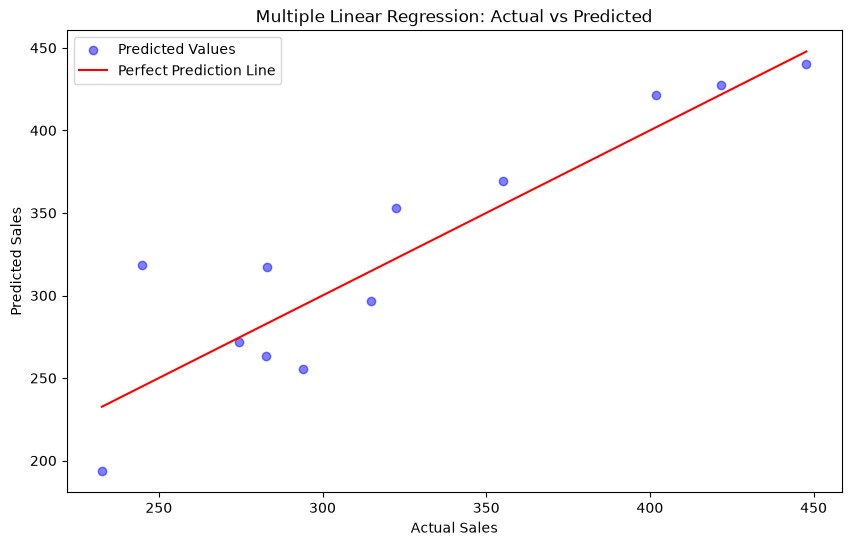

In [24]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, color='blue', alpha=0.5,
            label='Predicted Values')

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', label='Perfect Prediction Line')

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')


plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.legend()
plt.show()
           


           